# DX799 O1 - Week 4 Jupyter Notebook: Logistic Regression and Feature Scaling

## Digital Customer Journey and E-Commerce Retention Analytics

**Student:** Javed Aamer

### Goal

Week 4 moves from continuous outcomes to binary decisions. I use logistic regression to estimate four different probabilities across the customer journey:

- whether a behavior/order record adds an item to cart
- whether a customer churns
- whether a product has high recent demand
- whether a review has relatively high sentiment

I also compare **unscaled numeric features, min-max normalization, and standardization**.

The purpose is not to assume scaling must produce a large AUC increase. The Week 4 lesson also emphasizes that scaling makes regularization more comparable across features and can improve numerical optimization. I therefore evaluate prediction, convergence, regularization strength, threshold choice, and interpretation.

## 1. Questions I want to answer

1. Are the four binary outcomes usable logistic-regression targets?
2. Does scaling change predictive quality, optimization behavior, or both?
3. Is normalization or standardization more useful?
4. How sensitive is each model to the regularization parameter `C`?
5. How much does the classification threshold change the precision-recall tradeoff?
6. Which standardized numeric predictors have the strongest associations with each positive outcome?

I preserve each table's natural grain. Behavior is split by customer and reviews are split by product so repeated observations from the same entity do not leak across the evaluation boundary.

## 2. Week 4 concepts from the lecture

### Logistic regression

Logistic regression estimates the probability of a binary outcome. The model is linear in the **log-odds**, so it is interpretable but can be restrictive when the real class boundary is strongly nonlinear.

### Feature scaling

The lecture compares two common approaches:

- **Min-max normalization:** puts a numeric feature on a common 0-to-1 scale.
- **Standardization:** recenters a feature around zero and measures it in standard-deviation units.

Scaling matters because variables such as price, tenure, rank, counts, and age are measured on very different scales. With regularization, a comparable scale makes the penalty more meaningful. Scaling can also improve convergence of iterative optimization.

### Additional cautions

The lecture also points out that logistic regression can be affected by multicollinearity and assumes reasonably independent observations. That is why I use grouped splitting when customers or products repeat.

In [1]:
from pathlib import Path
import re
import json
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss,
    roc_curve,
    precision_recall_curve,
    confusion_matrix,
)

RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

## 3. Load the four cleaned datasets

The four tables are treated as complementary parts of one e-commerce project rather than force-joined into one artificial table.

- **Behavior:** browsing and transaction activity
- **Churn:** customer retention
- **Products:** catalog and demand
- **Reviews:** post-purchase experience

Products and reviews share ASIN and can be linked when appropriate. Behavior and churn do not have a verified common customer key, so I keep them separate.

In [2]:
candidate_dirs = [
    Path("data"),
    Path("../data"),
    Path("data_pkg"),
    Path("../data_pkg"),
    Path("/mnt/data/dx799_rebuild/data/cleaned_week2_output"),
]

DATA_DIR = next(
    (p for p in candidate_dirs if (p / "behavior_clean.csv").exists()),
    None,
)

if DATA_DIR is None:
    raise FileNotFoundError("Could not find the four cleaned CSV files.")

behavior = pd.read_csv(DATA_DIR / "behavior_clean.csv", low_memory=False)
churn = pd.read_csv(DATA_DIR / "churn_clean.csv", low_memory=False)
products = pd.read_csv(DATA_DIR / "products_clean.csv", low_memory=False)
reviews = pd.read_csv(DATA_DIR / "reviews_clean.csv", low_memory=False)

print(f"Loaded data from: {DATA_DIR}")

Loaded data from: /mnt/data/dx799_rebuild/data/cleaned_week2_output


In [3]:
products["rating_stars_num"] = pd.to_numeric(
    products["rating_stars"].astype(str).str.extract(r"([0-9.]+)")[0],
    errors="coerce",
)

products["rating_count_num"] = pd.to_numeric(
    products["rating_count"]
        .astype(str)
        .str.replace(",", "", regex=False)
        .str.extract(r"([0-9]+)")[0],
    errors="coerce",
)

def parse_recent_purchases(value):
    match = re.search(r"([\d,.]+)\s*([Kk]?)", str(value))
    if not match:
        return np.nan

    number = float(match.group(1).replace(",", ""))
    return number * 1000 if match.group(2) else number

products["recent_purchases_num"] = products["recent_purchases"].map(parse_recent_purchases)

products["list_price_num"] = pd.to_numeric(
    products["list_price"]
        .astype(str)
        .str.replace(",", "", regex=False)
        .str.extract(r"\$([0-9.]+)")[0],
    errors="coerce",
)

products["discount_pct"] = np.where(
    products["list_price_num"] > 0,
    (products["list_price_num"] - products["price_value"])
    / products["list_price_num"],
    0,
)

products["main_rank"] = pd.to_numeric(
    products["best_sellers_rank"]
        .astype(str)
        .str.replace(",", "", regex=False)
        .str.extract(r"#([0-9]+)")[0],
    errors="coerce",
)

products["in_stock"] = (
    products["availability"]
    .astype(str)
    .str.lower()
    .str.contains("in stock")
    .astype(int)
)

products["description_len"] = products["product_description"].astype(str).str.len()
products["review_summary_len"] = products["customer_review_summary"].astype(str).str.len()

reviews["review_len"] = (
    reviews["cleaned_review_text"].astype(str).str.split().str.len()
)
reviews["verified_int"] = reviews["verifiedPurchase"].astype(int)

## 4. Define four classification decisions

Two outcomes already exist in the cleaned data:

- Behavior: `Add to Cart`
- Churn: `Churn`

For Products and Reviews I create project-specific binary decisions:

- **High product demand:** at least 300 recent purchases.
- **High review sentiment:** sentiment score above 0.30.

These thresholds create useful operational groups and keep those two tasks reasonably balanced. They are capstone analysis definitions, not externally validated ground truth.

In [4]:
products["high_demand"] = (
    products["recent_purchases_num"] >= 300
).astype(int)

reviews["high_sentiment"] = (
    reviews["sentiment_score"] > 0.30
).astype(int)

CLS_TASKS = {
    "Behavior": {
        "df": behavior,
        "target": "Add to Cart",
        "group": "Customer ID",
        "numeric": [
            "Browsing Time (min)",
            "Sales",
            "Quantity",
            "Discount",
            "Age",
        ],
        "categorical": [
            "Segment",
            "Ship Mode",
            "Product Category",
            "Order Priority",
            "Like",
            "Share",
        ],
    },
    "Churn": {
        "df": churn,
        "target": "Churn",
        "group": None,
        "numeric": [
            "Tenure",
            "WarehouseToHome",
            "HourSpendOnApp",
            "NumberOfDeviceRegistered",
            "SatisfactionScore",
            "NumberOfAddress",
            "Complain",
            "OrderAmountHikeFromlastYear",
            "CouponUsed",
            "OrderCount",
            "DaySinceLastOrder",
            "CashbackAmount",
        ],
        "categorical": [
            "PreferredLoginDevice",
            "PreferredPaymentMode",
            "PreferedOrderCat",
            "MaritalStatus",
            "CityTier",
            "Gender",
        ],
    },
    "Products": {
        "df": products,
        "target": "high_demand",
        "group": None,
        "numeric": [
            "price_value",
            "rating_stars_num",
            "rating_count_num",
            "discount_pct",
            "main_rank",
            "rank_1",
            "description_len",
            "review_summary_len",
        ],
        "categorical": ["in_stock"],
    },
    "Reviews": {
        "df": reviews,
        "target": "high_sentiment",
        "group": "productASIN",
        "numeric": [
            "rating",
            "helpfulVoteCount",
            "reviewPosition",
            "review_len",
            "verified_int",
        ],
        "categorical": [],
    },
}

In [5]:
role_table = pd.DataFrame(
    {
        "Dataset": ["Behavior", "Churn", "Products", "Reviews"],
        "Rows": [len(behavior), len(churn), len(products), len(reviews)],
        "Grain": ["order/activity", "customer", "product", "review"],
        "Positive outcome": [
            "Added to cart",
            "Churned",
            "High recent demand",
            "Sentiment > 0.30",
        ],
        "Decision use": [
            "conversion / engagement",
            "retention outreach",
            "catalog demand prioritization",
            "post-purchase experience",
        ],
    }
)

display(role_table)

,Dataset,Rows,Grain,Positive outcome,Decision use
0,Behavior,51289,order/activity,Added to cart,conversion / engagement
1,Churn,5630,customer,Churned,retention outreach
2,Products,728,product,High recent demand,catalog demand prioritization
3,Reviews,6327,review,Sentiment > 0.30,post-purchase experience


## 5. Class balance

Accuracy can be misleading when one class dominates.

Churn is the most imbalanced outcome in this notebook, so PR-AUC, recall, F1, and balanced accuracy matter more than raw accuracy alone. Products and Reviews are nearly balanced, while Behavior has more positive than negative examples.

,Dataset,Negative class,Positive class,Positive prevalence
0,Behavior,17093,34196,0.6667
1,Churn,4682,948,0.1684
2,Products,395,333,0.4574
3,Reviews,3170,3157,0.4990


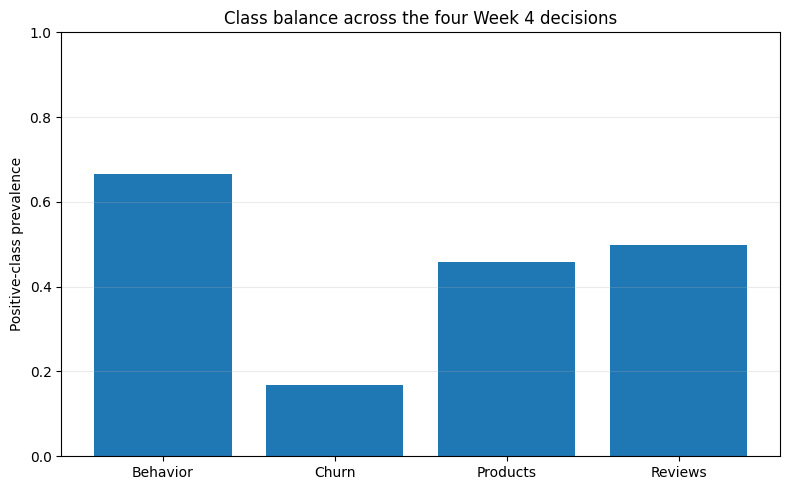

In [6]:
balance_rows = []

for name, task in CLS_TASKS.items():
    y = task["df"][task["target"]].astype(int)

    balance_rows.append(
        {
            "Dataset": name,
            "Negative class": int((y == 0).sum()),
            "Positive class": int((y == 1).sum()),
            "Positive prevalence": y.mean(),
        }
    )

class_balance = pd.DataFrame(balance_rows)
display(class_balance.round(4))

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(
    class_balance["Dataset"],
    class_balance["Positive prevalence"],
)
ax.set_ylim(0, 1)
ax.set_ylabel("Positive-class prevalence")
ax.set_title("Class balance across the four Week 4 decisions")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 6. How different are the numeric feature scales?

Before scaling, I compare the spread of numeric predictors within each dataset.

I summarize this as the ratio between the largest and smallest nonzero standard deviation. A large ratio means the optimizer and regularization penalty are seeing variables on very different numeric scales.

,Dataset,Smallest numeric SD,Largest numeric SD,Largest / smallest SD
0,Behavior,0.0140,65.7810,"4,660.6730"
1,Churn,0.4510,49.2070,109.0080
2,Products,0.3290,"703,344.3420","2,139,672.2890"
3,Reviews,0.1570,46.3640,295.2870


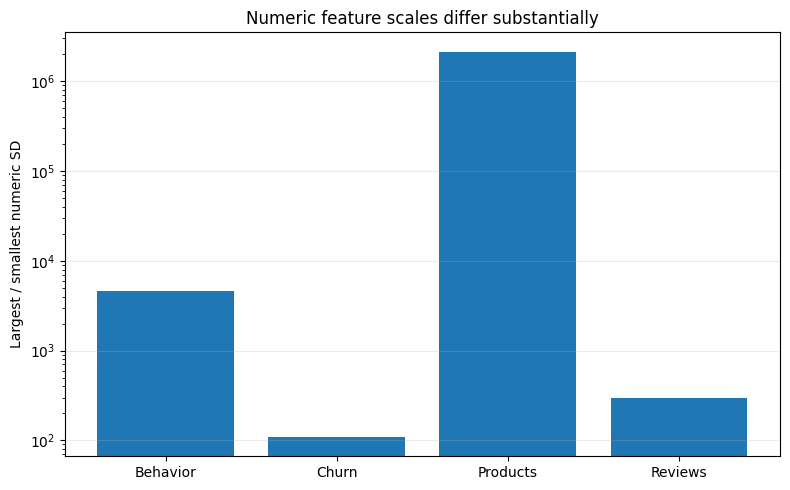

In [7]:
scale_rows = []

for name, task in CLS_TASKS.items():
    numeric = (
        task["df"][task["numeric"]]
        .apply(pd.to_numeric, errors="coerce")
    )

    stds = numeric.std().replace(0, np.nan).dropna()

    scale_rows.append(
        {
            "Dataset": name,
            "Smallest numeric SD": stds.min(),
            "Largest numeric SD": stds.max(),
            "Largest / smallest SD": stds.max() / stds.min(),
        }
    )

scale_summary = pd.DataFrame(scale_rows)
display(scale_summary.round(3))

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(
    scale_summary["Dataset"],
    scale_summary["Largest / smallest SD"],
)
ax.set_yscale("log")
ax.set_ylabel("Largest / smallest numeric SD")
ax.set_title("Numeric feature scales differ substantially")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 7. Train, validation, and test design

I use separate partitions for three jobs:

- **Training:** fit models
- **Validation:** choose scaling, `C`, and the probability threshold
- **Test:** final evaluation after those choices are fixed

Churn and Products are stratified by the target.

Behavior is grouped by `Customer ID`, and Reviews are grouped by `productASIN`. This is important because repeated records from the same customer or product should not appear on both sides of the evaluation boundary.

In [8]:
def split_three(df, target, group_col=None):
    index = np.arange(len(df))

    if group_col is not None:
        groups = df[group_col].astype(str).values

        first = GroupShuffleSplit(
            n_splits=1,
            test_size=0.20,
            random_state=RANDOM_STATE,
        )
        train_validation, test = next(
            first.split(index, groups=groups)
        )

        second = GroupShuffleSplit(
            n_splits=1,
            test_size=0.25,
            random_state=RANDOM_STATE + 1,
        )
        train_relative, validation_relative = next(
            second.split(
                train_validation,
                groups=groups[train_validation],
            )
        )

        train = train_validation[train_relative]
        validation = train_validation[validation_relative]

    else:
        y = df[target].astype(int).values

        train_validation, test = train_test_split(
            index,
            test_size=0.20,
            random_state=RANDOM_STATE,
            stratify=y,
        )

        train, validation = train_test_split(
            train_validation,
            test_size=0.25,
            random_state=RANDOM_STATE + 1,
            stratify=y[train_validation],
        )

    return train, validation, test


def classification_metrics(y_true, probability, prediction):
    return {
        "ROC_AUC": roc_auc_score(y_true, probability),
        "PR_AUC": average_precision_score(y_true, probability),
        "Accuracy": accuracy_score(y_true, prediction),
        "Balanced_Accuracy": balanced_accuracy_score(y_true, prediction),
        "Precision": precision_score(y_true, prediction, zero_division=0),
        "Recall": recall_score(y_true, prediction, zero_division=0),
        "F1": f1_score(y_true, prediction, zero_division=0),
        "Log_Loss": log_loss(y_true, probability),
    }

In [9]:
def make_preprocessor(task, scaling):
    numeric_steps = [
        ("imputer", SimpleImputer(strategy="median")),
    ]

    if scaling == "Min-max":
        numeric_steps.append(
            ("scaler", MinMaxScaler())
        )
    elif scaling == "Standardized":
        numeric_steps.append(
            ("scaler", StandardScaler())
        )

    numeric_pipe = Pipeline(numeric_steps)

    transformers = [
        ("numeric", numeric_pipe, task["numeric"]),
    ]

    if task["categorical"]:
        categorical_pipe = Pipeline(
            [
                ("imputer", SimpleImputer(strategy="most_frequent")),
                (
                    "onehot",
                    OneHotEncoder(handle_unknown="ignore", drop="first"),
                ),
            ]
        )

        transformers.append(
            ("categorical", categorical_pipe, task["categorical"])
        )

    return ColumnTransformer(transformers)


def make_logistic_model(task_name, C, max_iter=5000):
    return LogisticRegression(
        C=C,
        penalty="l2",
        solver="lbfgs",
        max_iter=max_iter,
        class_weight="balanced" if task_name == "Churn" else None,
    )

## 8. Compare unscaled, min-max, and standardized logistic regression

I first compare the three scaling strategies with the **same logistic regression setting (`C = 1`)**. Keeping `C` fixed isolates the effect of preprocessing rather than mixing scaling and hyperparameter tuning in the same comparison.

I record validation ROC-AUC, PR-AUC, log loss, and optimizer iterations. The Week 4 lesson makes this distinction important: scaling may improve numerical optimization even when the ranking metrics barely move.

After this comparison, I standardize the numeric predictors and tune `C` separately.

In [10]:
SCALING_OPTIONS = ["Unscaled", "Min-max", "Standardized"]

prepared = {}
scaling_summary_rows = []

for dataset_name, task in CLS_TASKS.items():
    df = task["df"]

    train_idx, validation_idx, test_idx = split_three(
        df,
        task["target"],
        task["group"],
    )

    prepared[dataset_name] = {
        "train_idx": train_idx,
        "validation_idx": validation_idx,
        "test_idx": test_idx,
    }

    y_train = df.iloc[train_idx][task["target"]].astype(int).values
    y_validation = df.iloc[validation_idx][task["target"]].astype(int).values

    for scaling in SCALING_OPTIONS:
        preprocessor = make_preprocessor(task, scaling)

        X_train = preprocessor.fit_transform(df.iloc[train_idx])
        X_validation = preprocessor.transform(df.iloc[validation_idx])

        model = make_logistic_model(dataset_name, C=1.0, max_iter=2000)
        model.fit(X_train, y_train)

        probability = model.predict_proba(X_validation)[:, 1]

        scaling_summary_rows.append(
            {
                "Dataset": dataset_name,
                "Scaling": scaling,
                "C": 1.0,
                "Validation ROC-AUC": roc_auc_score(y_validation, probability),
                "Validation PR-AUC": average_precision_score(y_validation, probability),
                "Validation Log Loss": log_loss(y_validation, probability),
                "Optimizer iterations": int(model.n_iter_[0]),
            }
        )

scaling_summary = pd.DataFrame(scaling_summary_rows)
display(scaling_summary.round(4))

,Dataset,Scaling,C,Validation ROC-AUC,Validation PR-AUC,Validation Log Loss,Optimizer iterations
0,Behavior,Unscaled,1.0000,0.7525,0.8744,0.5380,604
1,Behavior,Min-max,1.0000,0.7522,0.8742,0.5381,19
2,Behavior,Standardized,1.0000,0.7522,0.8742,0.5381,23
3,Churn,Unscaled,1.0000,0.8859,0.6894,0.4311,1614
4,Churn,Min-max,1.0000,0.8858,0.6972,0.4296,47
5,Churn,Standardized,1.0000,0.8859,0.6899,0.4312,35
6,Products,Unscaled,1.0000,0.6879,0.6268,0.6466,548
7,Products,Min-max,1.0000,0.6760,0.6339,0.6317,23
8,Products,Standardized,1.0000,0.6811,0.6250,0.6408,19
9,Reviews,Unscaled,1.0000,0.7622,0.7447,0.5866,42


## 9. What did scaling actually change?

A normal grouped AUC chart would be visually misleading because many scores are very close.

I therefore show two more useful views:

1. **change in the relevant validation metric versus the unscaled model**
2. **optimizer iterations**

This separates predictive value from numerical efficiency.

,Dataset,Scaling,Metric,Absolute change vs unscaled
0,Behavior,Unscaled,Validation ROC-AUC,0.0000
1,Behavior,Min-max,Validation ROC-AUC,-0.0002
2,Behavior,Standardized,Validation ROC-AUC,-0.0002
3,Churn,Unscaled,Validation PR-AUC,0.0000
4,Churn,Min-max,Validation PR-AUC,0.0078
5,Churn,Standardized,Validation PR-AUC,0.0004
6,Products,Unscaled,Validation ROC-AUC,0.0000
7,Products,Min-max,Validation ROC-AUC,-0.0119
8,Products,Standardized,Validation ROC-AUC,-0.0068
9,Reviews,Unscaled,Validation ROC-AUC,0.0000


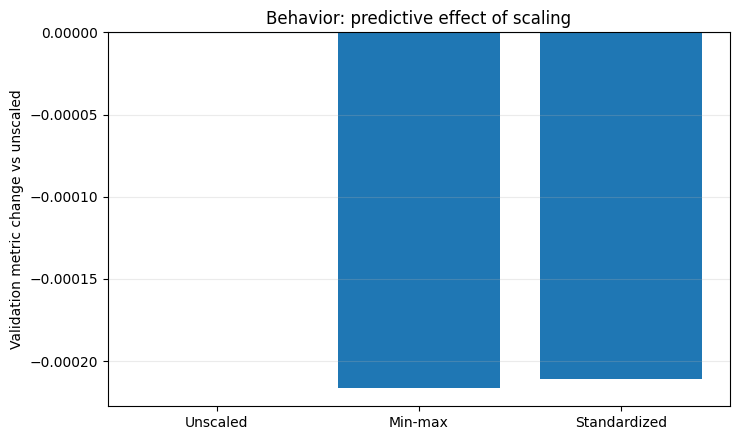

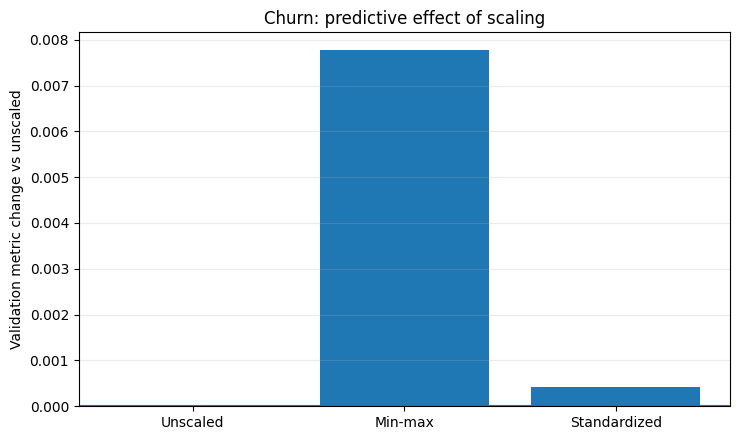

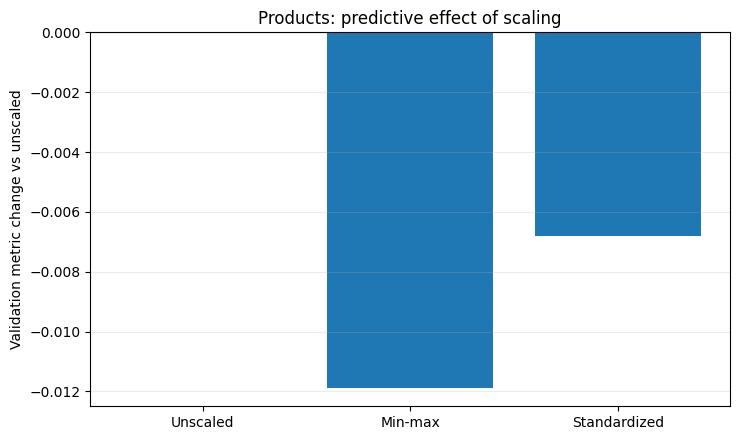

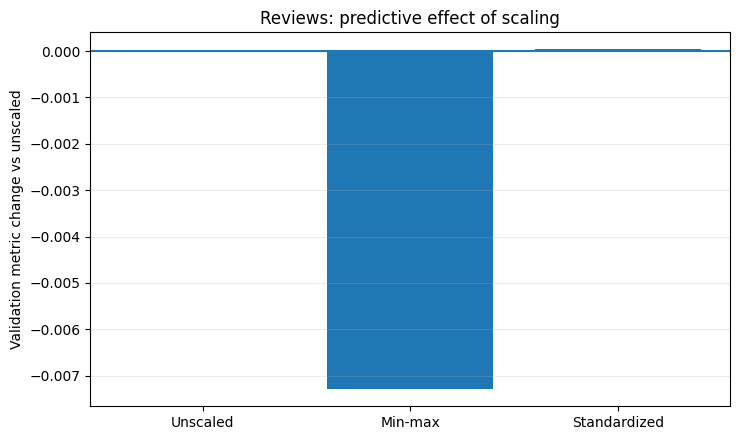

In [11]:
relative_scaling_rows = []

for dataset_name in CLS_TASKS:
    subset = scaling_summary[
        scaling_summary["Dataset"] == dataset_name
    ]

    metric = (
        "Validation PR-AUC"
        if dataset_name == "Churn"
        else "Validation ROC-AUC"
    )

    baseline = subset.loc[
        subset["Scaling"] == "Unscaled",
        metric,
    ].iloc[0]

    for _, row in subset.iterrows():
        relative_scaling_rows.append(
            {
                "Dataset": dataset_name,
                "Scaling": row["Scaling"],
                "Metric": metric,
                "Absolute change vs unscaled": row[metric] - baseline,
            }
        )

relative_scaling = pd.DataFrame(relative_scaling_rows)
display(relative_scaling.round(5))

for dataset_name in CLS_TASKS:
    subset = relative_scaling[
        relative_scaling["Dataset"] == dataset_name
    ]

    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    ax.bar(
        subset["Scaling"],
        subset["Absolute change vs unscaled"],
    )
    ax.axhline(0)
    ax.set_ylabel("Validation metric change vs unscaled")
    ax.set_title(f"{dataset_name}: predictive effect of scaling")
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()

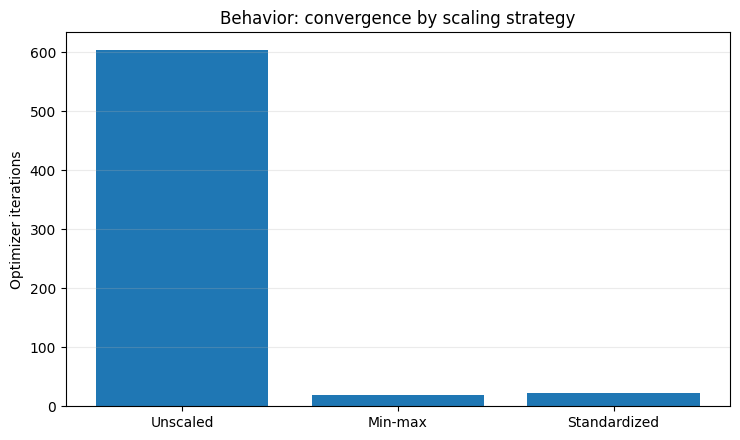

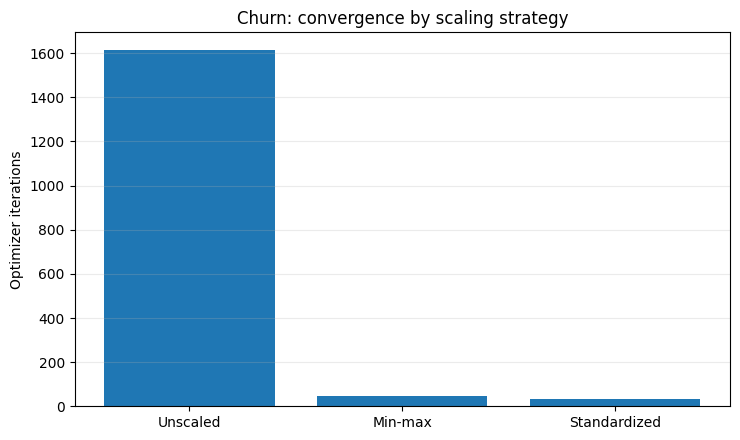

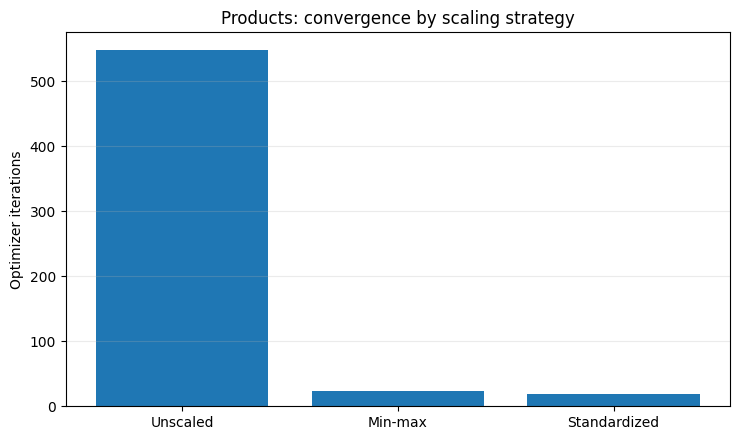

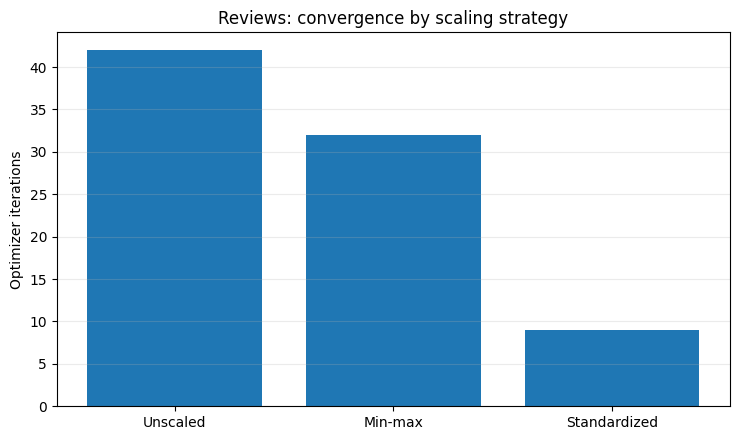

In [12]:
for dataset_name in CLS_TASKS:
    subset = scaling_summary[
        scaling_summary["Dataset"] == dataset_name
    ]

    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    ax.bar(
        subset["Scaling"],
        subset["Optimizer iterations"],
    )
    ax.set_ylabel("Optimizer iterations")
    ax.set_title(f"{dataset_name}: convergence by scaling strategy")
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()

### Scaling interpretation

The main Week 4 result is that scaling does not need to create a large AUC improvement to be useful.

The validation rankings are very close for several tasks, while convergence improves dramatically. For example, the unscaled Behavior and Product fits require hundreds of optimizer iterations, whereas the standardized versions converge in only a few dozen. Churn is a useful exception: min-max scaling gives the highest validation PR-AUC at `C = 1`, although the difference from standardization is modest.

For the remainder of the notebook I use **standardization** as a common modeling strategy because it gives efficient convergence, supports comparable regularization across numeric features, and makes numeric coefficients easier to interpret. I keep the small metric differences visible rather than claiming standardization is always the best predictive choice.

## 10. Regularization-strength sensitivity

After the scaling comparison, I use **standardized numeric predictors** and tune the regularization parameter `C`. This keeps the scaling choice fixed while I study the penalty strength.

I use a logarithmic grid from strong to weak regularization. For Churn I select `C` with validation PR-AUC because the positive class is uncommon. For Behavior, Products, and Reviews I use validation ROC-AUC.

A sharp peak would mean the model is sensitive to regularization strength. A broad plateau means several nearby `C` values are practically equivalent.

,Dataset,Best C
0,Behavior,31.6228
1,Churn,0.1778
2,Products,1.0000
3,Reviews,1.0000


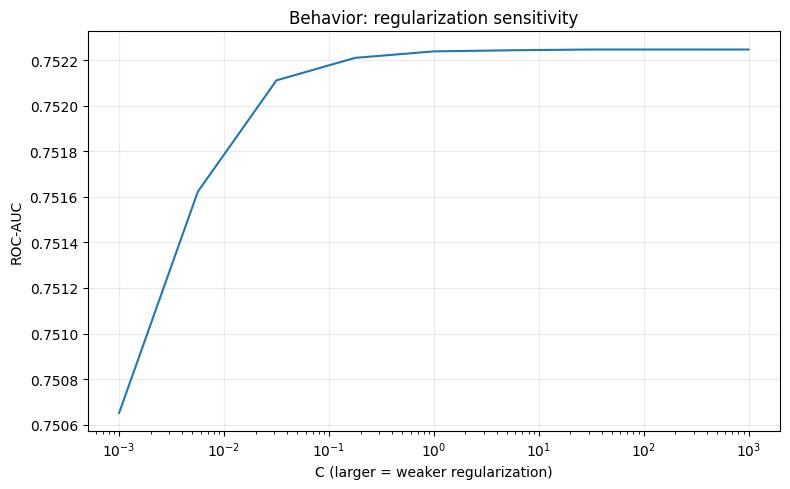

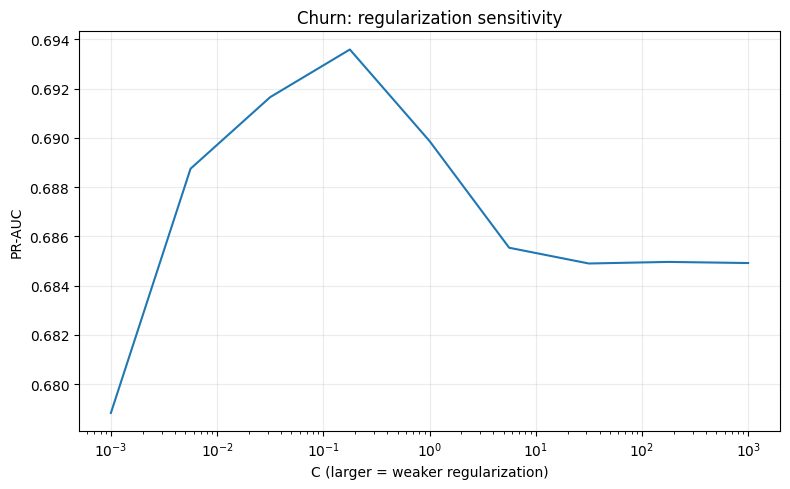

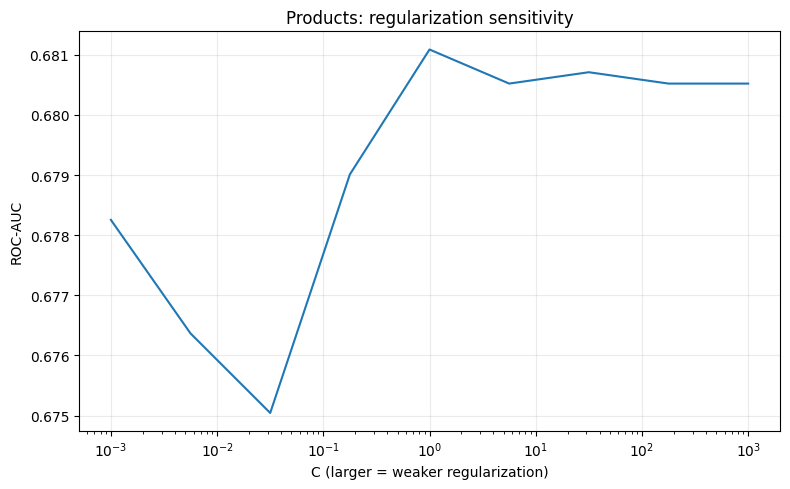

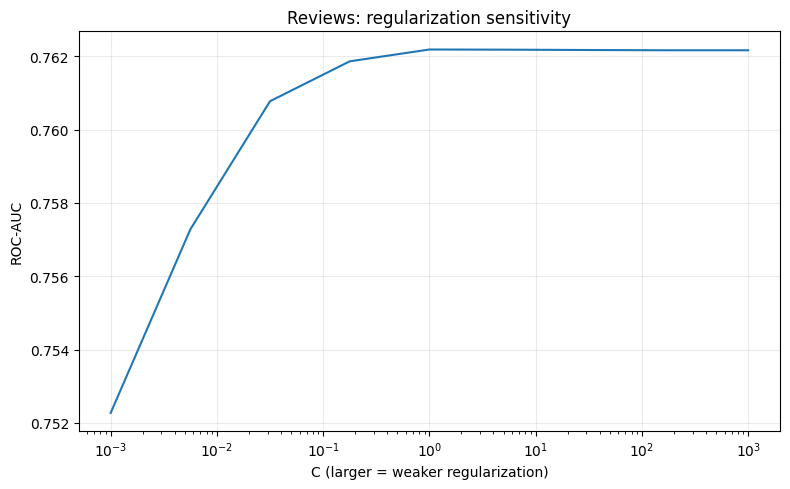

In [13]:
C_VALUES = np.logspace(-3, 3, 9)
search_rows = []
best_c_by_dataset = {}

for dataset_name, task in CLS_TASKS.items():
    df = task["df"]
    idx = prepared[dataset_name]

    preprocessor = make_preprocessor(task, "Standardized")
    X_train = preprocessor.fit_transform(df.iloc[idx["train_idx"]])
    X_validation = preprocessor.transform(df.iloc[idx["validation_idx"]])

    y_train = df.iloc[idx["train_idx"]][task["target"]].astype(int).values
    y_validation = df.iloc[idx["validation_idx"]][task["target"]].astype(int).values

    candidates = []

    for C in C_VALUES:
        model = make_logistic_model(dataset_name, C=C, max_iter=2000)
        model.fit(X_train, y_train)

        probability = model.predict_proba(X_validation)[:, 1]
        roc = roc_auc_score(y_validation, probability)
        pr = average_precision_score(y_validation, probability)
        score = pr if dataset_name == "Churn" else roc

        search_rows.append(
            {
                "Dataset": dataset_name,
                "C": C,
                "Validation ROC-AUC": roc,
                "Validation PR-AUC": pr,
                "Tuning score": score,
                "Iterations": int(model.n_iter_[0]),
            }
        )
        candidates.append((score, C))

    best_c_by_dataset[dataset_name] = max(candidates, key=lambda row: row[0])[1]

search_results = pd.DataFrame(search_rows)

best_c_table = pd.DataFrame(
    [{"Dataset": name, "Best C": value} for name, value in best_c_by_dataset.items()]
)
display(best_c_table)

for dataset_name in CLS_TASKS:
    subset = search_results[search_results["Dataset"] == dataset_name]
    metric = "Validation PR-AUC" if dataset_name == "Churn" else "Validation ROC-AUC"

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(subset["C"], subset[metric])
    ax.set_xscale("log")
    ax.set_xlabel("C (larger = weaker regularization)")
    ax.set_ylabel(metric.replace("Validation ", ""))
    ax.set_title(f"{dataset_name}: regularization sensitivity")
    ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

## 11. Select a probability threshold

Logistic regression returns probabilities, so a yes/no action still requires a threshold.

I do **not** use the same threshold rule for every dataset. The class balance is different, so the decision objective should be different too.

- **Churn:** I select the validation threshold that maximizes F1 because I want a practical balance between finding churners and limiting false alarms.
- **Behavior, Products, Reviews:** I select the validation threshold that maximizes balanced accuracy. These tasks are much closer to balanced, and balanced accuracy prevents the threshold search from drifting toward a trivial majority-class prediction simply because that can inflate ordinary F1.

The selected threshold is still an operating point, not a permanent business rule. A production system could move it based on outreach capacity, inventory priorities, or the cost of false positives and false negatives.

In [14]:
selected_settings = {}
threshold_curves = {}

for dataset_name, task in CLS_TASKS.items():
    df = task["df"]
    idx = prepared[dataset_name]
    best_C = float(best_c_by_dataset[dataset_name])

    preprocessor = make_preprocessor(task, "Standardized")
    X_train = preprocessor.fit_transform(df.iloc[idx["train_idx"]])
    X_validation = preprocessor.transform(df.iloc[idx["validation_idx"]])

    y_train = df.iloc[idx["train_idx"]][task["target"]].astype(int).values
    y_validation = df.iloc[idx["validation_idx"]][task["target"]].astype(int).values

    model = make_logistic_model(dataset_name, best_C)
    model.fit(X_train, y_train)
    validation_probability = model.predict_proba(X_validation)[:, 1]

    threshold_rows = []
    for threshold in np.arange(0.10, 0.91, 0.05):
        prediction = (validation_probability >= threshold).astype(int)
        threshold_rows.append(
            {
                "Threshold": threshold,
                "Precision": precision_score(y_validation, prediction, zero_division=0),
                "Recall": recall_score(y_validation, prediction, zero_division=0),
                "F1": f1_score(y_validation, prediction, zero_division=0),
                "Balanced Accuracy": balanced_accuracy_score(y_validation, prediction),
            }
        )

    curve = pd.DataFrame(threshold_rows)
    criterion = "F1" if dataset_name == "Churn" else "Balanced Accuracy"
    best_threshold_row = curve.sort_values(criterion, ascending=False).iloc[0]
    threshold_curves[dataset_name] = curve

    selected_settings[dataset_name] = {
        "Best C": best_C,
        "Threshold": float(best_threshold_row["Threshold"]),
        "Threshold criterion": criterion,
        "Validation criterion value": float(best_threshold_row[criterion]),
    }

selected_settings_table = pd.DataFrame(
    [{"Dataset": name, **settings} for name, settings in selected_settings.items()]
)

display(selected_settings_table.round(4))

,Dataset,Best C,Threshold,Threshold criterion,Validation criterion value
0,Behavior,31.6228,0.8000,Balanced Accuracy,0.7384
1,Churn,0.1778,0.7000,F1,0.6355
2,Products,1.0000,0.3500,Balanced Accuracy,0.6480
3,Reviews,1.0000,0.5500,Balanced Accuracy,0.6982


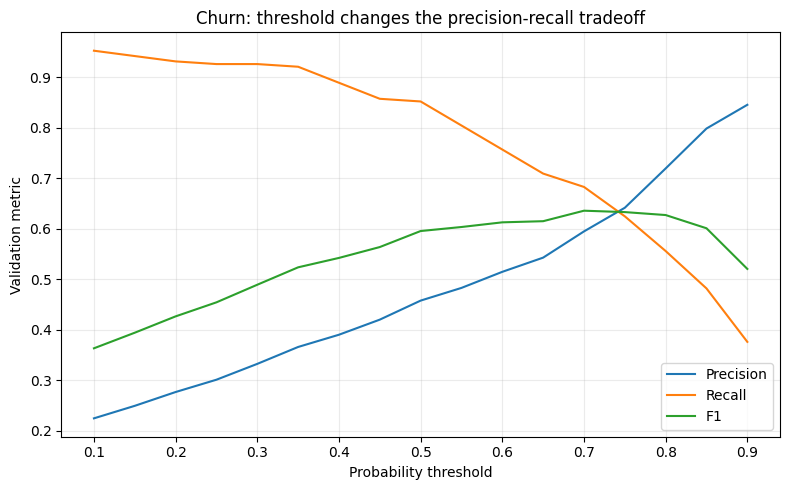

In [15]:
churn_thresholds = threshold_curves["Churn"]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    churn_thresholds["Threshold"],
    churn_thresholds["Precision"],
    label="Precision",
)
ax.plot(
    churn_thresholds["Threshold"],
    churn_thresholds["Recall"],
    label="Recall",
)
ax.plot(
    churn_thresholds["Threshold"],
    churn_thresholds["F1"],
    label="F1",
)

ax.set_xlabel("Probability threshold")
ax.set_ylabel("Validation metric")
ax.set_title("Churn: threshold changes the precision-recall tradeoff")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

## 12. Final standardized logistic models

The modeling decisions are now fixed.

For each dataset I combine training and validation, refit the preprocessing, fit logistic regression with the selected `C`, apply the selected threshold, and evaluate once on the untouched test set.

In [16]:
final_rows = []
final_models = {}
final_predictions = {}

for dataset_name, task in CLS_TASKS.items():
    df = task["df"]
    idx = prepared[dataset_name]
    settings = selected_settings[dataset_name]

    train_validation_idx = np.concatenate(
        [idx["train_idx"], idx["validation_idx"]]
    )
    test_idx = idx["test_idx"]

    preprocessor = make_preprocessor(
        task,
        "Standardized",
    )

    X_train_validation = preprocessor.fit_transform(
        df.iloc[train_validation_idx]
    )
    X_test = preprocessor.transform(
        df.iloc[test_idx]
    )

    y_train_validation = (
        df.iloc[train_validation_idx][task["target"]]
        .astype(int)
        .values
    )
    y_test = (
        df.iloc[test_idx][task["target"]]
        .astype(int)
        .values
    )

    model = make_logistic_model(
        dataset_name,
        settings["Best C"],
    )
    model.fit(X_train_validation, y_train_validation)

    probability = model.predict_proba(X_test)[:, 1]
    prediction = (
        probability >= settings["Threshold"]
    ).astype(int)

    final_rows.append(
        {
            "Dataset": dataset_name,
            "C": settings["Best C"],
            "Threshold": settings["Threshold"],
            "Iterations": int(model.n_iter_[0]),
            **classification_metrics(
                y_test,
                probability,
                prediction,
            ),
        }
    )

    final_models[dataset_name] = {
        "preprocessor": preprocessor,
        "model": model,
    }

    final_predictions[dataset_name] = {
        "y_test": y_test,
        "probability": probability,
        "prediction": prediction,
    }

final_results = pd.DataFrame(final_rows)
display(final_results.round(4))

,Dataset,C,Threshold,Iterations,ROC_AUC,PR_AUC,Accuracy,Balanced_Accuracy,Precision,Recall,F1,Log_Loss
0,Behavior,31.6228,0.8000,21,0.7475,0.8630,0.6794,0.7372,0.9282,0.5595,0.6981,0.5457
1,Churn,0.1778,0.7000,29,0.8849,0.6829,0.8632,0.7961,0.5789,0.6947,0.6316,0.4334
2,Products,1.0000,0.3500,18,0.6902,0.6335,0.5822,0.5969,0.5306,0.7761,0.6303,0.6459
3,Reviews,1.0000,0.5500,8,0.7634,0.7346,0.7067,0.7067,0.7058,0.7000,0.7029,0.6007


## 13. Final probability metrics

ROC-AUC and PR-AUC answer different questions.

- **ROC-AUC** measures how well the model ranks positives above negatives across thresholds.
- **PR-AUC** focuses more directly on positive-class retrieval.

Because PR-AUC depends on prevalence, I compare each result with its own positive-class baseline rather than comparing raw PR-AUC values across unrelated tasks.

,Dataset,ROC-AUC,PR-AUC,Positive prevalence,PR-AUC lift over prevalence
0,Behavior,0.7475,0.8630,0.6667,0.1963
1,Churn,0.8849,0.6829,0.1684,0.5145
2,Products,0.6902,0.6335,0.4574,0.1761
3,Reviews,0.7634,0.7346,0.4990,0.2356


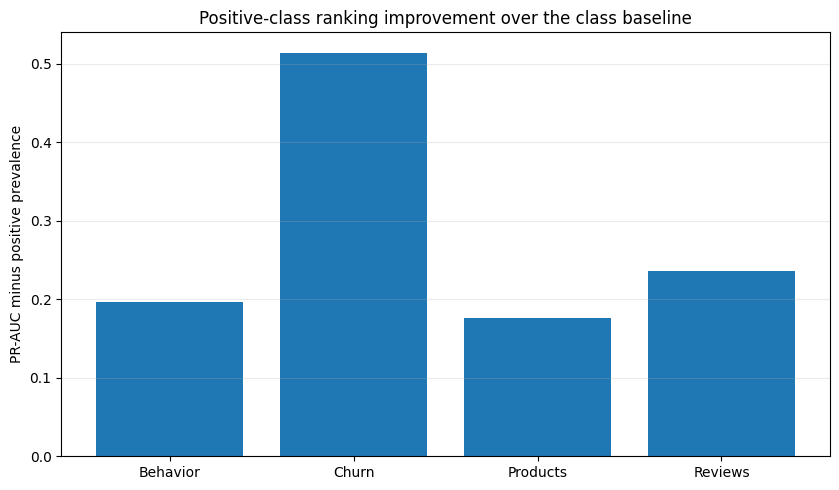

In [17]:
probability_metric_rows = []

for dataset_name in CLS_TASKS:
    prevalence = float(
        CLS_TASKS[dataset_name]["df"][
            CLS_TASKS[dataset_name]["target"]
        ].mean()
    )

    row = final_results[
        final_results["Dataset"] == dataset_name
    ].iloc[0]

    probability_metric_rows.append(
        {
            "Dataset": dataset_name,
            "ROC-AUC": row["ROC_AUC"],
            "PR-AUC": row["PR_AUC"],
            "Positive prevalence": prevalence,
            "PR-AUC lift over prevalence": row["PR_AUC"] - prevalence,
        }
    )

probability_metrics = pd.DataFrame(
    probability_metric_rows
)

display(probability_metrics.round(4))

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.bar(
    probability_metrics["Dataset"],
    probability_metrics["PR-AUC lift over prevalence"],
)
ax.set_ylabel("PR-AUC minus positive prevalence")
ax.set_title("Positive-class ranking improvement over the class baseline")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 14. Churn diagnostics

Churn gets the most detailed probability diagnostics because it is the main retention decision and the most imbalanced target.

I do not repeat the same three plots mechanically for the balanced Product and Review targets.

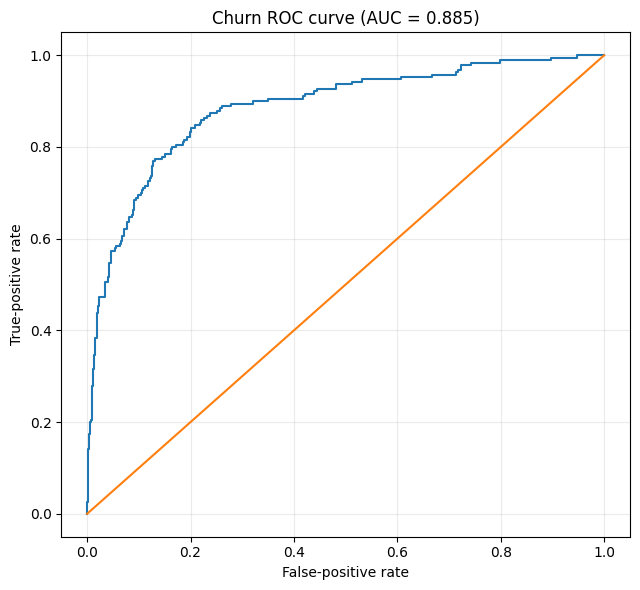

In [18]:
churn_final = final_predictions["Churn"]

fpr, tpr, _ = roc_curve(
    churn_final["y_test"],
    churn_final["probability"],
)

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot(fpr, tpr)
ax.plot([0, 1], [0, 1])
ax.set_xlabel("False-positive rate")
ax.set_ylabel("True-positive rate")
ax.set_title(
    f"Churn ROC curve (AUC = {final_results.loc[final_results['Dataset']=='Churn','ROC_AUC'].iloc[0]:.3f})"
)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

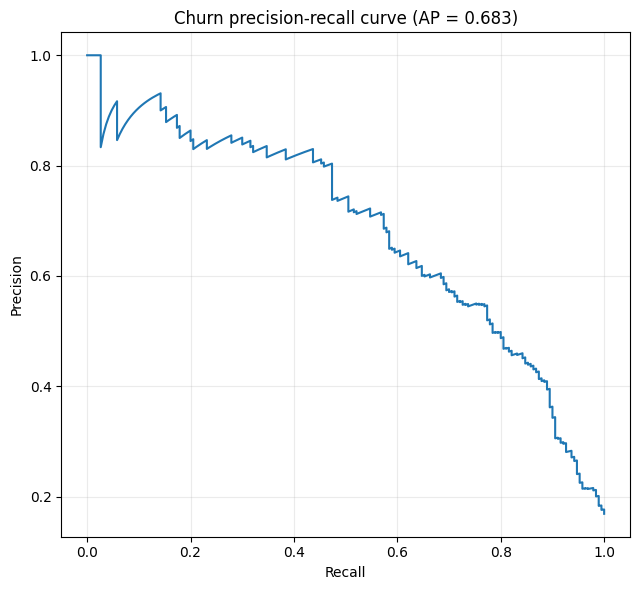

In [19]:
precision, recall, _ = precision_recall_curve(
    churn_final["y_test"],
    churn_final["probability"],
)

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot(recall, precision)
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title(
    f"Churn precision-recall curve (AP = {final_results.loc[final_results['Dataset']=='Churn','PR_AUC'].iloc[0]:.3f})"
)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

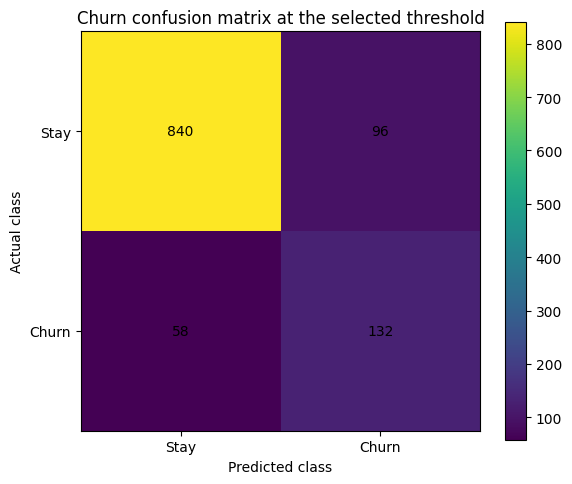

In [20]:
cm = confusion_matrix(
    churn_final["y_test"],
    churn_final["prediction"],
)

fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(cm)

ax.set_xticks([0, 1])
ax.set_xticklabels(["Stay", "Churn"])
ax.set_yticks([0, 1])
ax.set_yticklabels(["Stay", "Churn"])

for row in range(cm.shape[0]):
    for col in range(cm.shape[1]):
        ax.text(
            col,
            row,
            str(cm[row, col]),
            ha="center",
            va="center",
        )

ax.set_xlabel("Predicted class")
ax.set_ylabel("Actual class")
ax.set_title("Churn confusion matrix at the selected threshold")
fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.show()

## 15. Standardized numeric coefficients

Standardization makes numeric coefficients easier to compare within each model.

A positive coefficient means higher values are associated with higher log-odds of the positive outcome after controlling for the other included predictors. A negative coefficient means the opposite.

These are predictive associations, not causal effects.

In [21]:
top_coefficient_rows = []

for dataset_name, task in CLS_TASKS.items():
    preprocessor = final_models[dataset_name]["preprocessor"]
    model = final_models[dataset_name]["model"]

    feature_names = preprocessor.get_feature_names_out()
    coefficients = model.coef_.ravel()

    table = pd.DataFrame(
        {
            "Feature": feature_names,
            "Coefficient": coefficients,
        }
    )

    numeric = table[
        table["Feature"].str.startswith("numeric__")
    ].copy()

    numeric["Feature"] = (
        numeric["Feature"]
        .str.replace("numeric__", "", regex=False)
    )
    numeric["Absolute coefficient"] = (
        numeric["Coefficient"].abs()
    )

    for _, row in (
        numeric.sort_values(
            "Absolute coefficient",
            ascending=False,
        )
        .head(5)
        .iterrows()
    ):
        top_coefficient_rows.append(
            {
                "Dataset": dataset_name,
                "Feature": row["Feature"],
                "Coefficient": row["Coefficient"],
                "Odds ratio": np.exp(row["Coefficient"]),
            }
        )

top_numeric_coefficients = pd.DataFrame(
    top_coefficient_rows
)

display(
    top_numeric_coefficients
    .sort_values(
        ["Dataset", "Coefficient"],
        ascending=[True, False],
    )
    .round(4)
)

,Dataset,Feature,Coefficient,Odds ratio
0,Behavior,Browsing Time (min),0.1164,1.1234
1,Behavior,Sales,0.0229,1.0232
3,Behavior,Discount,0.0100,1.0100
4,Behavior,Quantity,0.0068,1.0068
2,Behavior,Age,-0.0183,0.9819
6,Churn,Complain,0.6915,1.9968
8,Churn,NumberOfAddress,0.5596,1.7499
9,Churn,DaySinceLastOrder,-0.3923,0.6755
7,Churn,CashbackAmount,-0.5686,0.5663
5,Churn,Tenure,-1.4539,0.2337


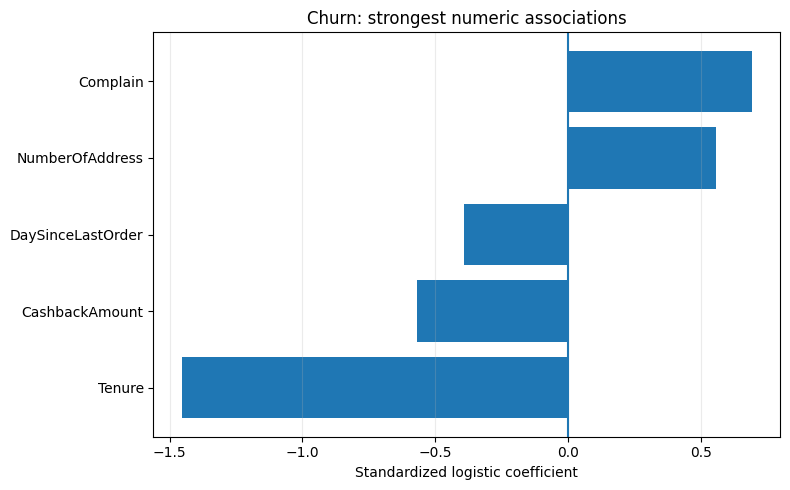

In [22]:
churn_coef = (
    top_numeric_coefficients[
        top_numeric_coefficients["Dataset"] == "Churn"
    ]
    .sort_values("Coefficient")
)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(
    churn_coef["Feature"],
    churn_coef["Coefficient"],
)
ax.axvline(0)
ax.set_xlabel("Standardized logistic coefficient")
ax.set_title("Churn: strongest numeric associations")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

## 16. Dataset-by-dataset interpretation

### Behavior

The model estimates whether an activity/order record adds an item to cart. Grouping by customer avoids evaluating the model on records from customers it already saw during training.

### Churn

This is the most decision-critical Week 4 model. PR-AUC, recall, and threshold choice matter more than raw accuracy because churn is uncommon. The model provides a useful risk ranking, but the operational threshold should ultimately reflect outreach cost and capacity.

### Products

The high-demand target turns recent purchase volume into a catalog-prioritization decision. The model asks whether price, rating, rank, availability, and content characteristics separate higher-demand products.

### Reviews

The high-sentiment model uses structured review metadata. Rating is expected to carry substantial signal, but this should not be treated as a full text sentiment model because the review language itself is not included.

## 17. What I learned

The strongest Week 4 lesson is that **feature scaling and classification performance are not the same question**.

Scaling may change ROC-AUC or PR-AUC only slightly while still being valuable because:

- regularization becomes more comparable across features
- optimization converges more cleanly
- standardized coefficients are easier to compare
- later distance- and margin-based models depend even more strongly on scale

Threshold choice is also part of the modeling decision. A logistic model gives probabilities, but the business still decides where to act.

Logistic regression is therefore a useful transparent probability baseline. If later nonlinear models improve substantially, that would suggest the linear log-odds boundary is too restrictive rather than merely poorly tuned.

## 18. Overfitting and leakage controls

1. The test set is separated before model-selection decisions.
2. Churn and Products use target-stratified splits.
3. Behavior is grouped by customer.
4. Reviews are grouped by product.
5. Imputation, scaling, and encoding are fit on training data during tuning.
6. `C` is selected on validation data.
7. Thresholds are selected on validation data.
8. Final models are evaluated once on untouched test data.
9. I report probability metrics as well as threshold-dependent classification metrics.

The grouped splits are especially important for the Week 4 independence issue.

## 19. Limitations

- Logistic regression is linear in the log-odds unless nonlinear terms are added.
- Multicollinearity can still make individual coefficients unstable.
- Churn class weights and threshold choice affect the final operating point.
- Product and review binary labels are project-defined, not externally validated ground truth.
- The product dataset is relatively small.
- The review model does not use the review text itself.
- Scaling cannot fix omitted variables or a misspecified functional form.
- Coefficients are associations rather than causal effects.

## 20. Course source and reproducibility

### Course sources

- DX799 O1, Week 4 Overview
- Week 4 lesson: **Logistic Regression and Feature Scaling**
- Week 4 Jupyter Notebook: **Logistic Regression and Feature Scaling**

The course lesson is the basis for the logistic-probability interpretation, normalization versus standardization, scaling and regularization discussion, and the caution about independent observations.

### External reference

scikit-learn developers, **LogisticRegression** and preprocessing documentation  
https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html  
https://scikit-learn.org/stable/modules/preprocessing.html

### Reproducibility

- Random seed: 42
- Final test share: 20%
- Validation share: 20% of the full data
- Scaling comparison: unscaled, min-max, standardized
- Penalty: L2
- Solver: `lbfgs`
- `C` grid: 0.001 through 1000 on a logarithmic scale
- Churn tuning metric: validation PR-AUC
- Other tuning metric: validation ROC-AUC
- Threshold metric: validation F1 for Churn; validation balanced accuracy for Behavior, Products, and Reviews
- Churn uses balanced class weights
- Behavior is grouped by `Customer ID`
- Reviews are grouped by `productASIN`

In [23]:
Path("outputs").mkdir(exist_ok=True)

summary = {
    "week": 4,
    "topic": "Logistic regression and feature scaling",
    "scaling_summary": scaling_summary.to_dict(orient="records"),
    "regularization_search": search_results.to_dict(orient="records"),
    "selected_settings": selected_settings_table.to_dict(orient="records"),
    "final_results": final_results.to_dict(orient="records"),
}

Path("outputs/week4_summary.json").write_text(
    json.dumps(summary, indent=2)
)

print("Saved outputs/week4_summary.json")

Saved outputs/week4_summary.json
